# COURSE PROJECT: GRAPH SIGNAL RECOVERY

## I. Problem Statement

A sensor network is represented by an **undirected, connected, weighted graph** `G`. Each node corresponds to a sensor. At node `i`, the observed value `y[i]` is known, but it contains **measurement noise** and may include **a few outliers**. The data also includes 2D coordinates and the edges and weights of the sensor network.

**Objective:** use the graph structure and observed data to estimate the unknown true values at every node:

\[
\hat{x}=(\hat{x}_0,\ldots,\hat{x}_{n-1}).
\]

Your group must **formulate its own assumptions, propose a mathematical model/loss function, choose parameters and an optimization method**, and then export predictions for all nodes. No loss function or `lambda` is prescribed. You may use Python, scientific libraries, and AI, but you are responsible for verifying the results.

**Evaluation:** `x_hat` is compared against the true values `x_true`, *which the instructor keeps hidden*, using root mean squared error (RMSE). Do not confuse `y` (noisy observations) with `x_true` (the ground truth).


## II. COMPLETE INSTRUCTIONS FOR COMPLETING AND SUBMITTING THE ASSIGNMENT

**A. Group Setup**

1. Each group has approximately **7 students** (as assigned by the instructor) and submits **one assignment**. Enter **ALL group members' student IDs (MSSVs)** in exactly **one code cell in Section III**. Each student ID must be a string (`"..."`); preserve any leading zeros.
2. Choose **exactly one representative student ID** from the group list to obtain the data. The **last line** of the code cell in Section III is `MSSV_DAI_DIEN = NHOM_MSSV[0]`. To change the representative, reorder the list before running the cell. Do not try multiple student IDs to select an easier case.
3. Run the data-loading cell in Section IV to obtain your group's **`G`, `y`, and `positions`** from `public_cases.json`; run the visualization cell in Section V to view the graph. Keep this notebook and `public_cases.json` in the **same folder**. If the student ID does not match an existing case ID, the program automatically maps it deterministically (using modulo) to an existing case.

**B. Research and Solution**

4. You **must** explain your chosen model: assumptions; notation and variables; the loss formula; the meaning of each term; how parameters are selected; how the solution is computed/the optimization algorithm; how convergence or plausibility is checked; and the model's limitations. You may provide this explanation **directly in Section VI of the notebook** or in **a separate report**.
5. **Encouraged but optional:** include code that produces the `x_hat` vector in Section VII of the notebook so that your work can be run and reproduced. If the notebook does not contain solution code, your group must still submit the result vector and explain how it was obtained.
6. The result `x_hat` must contain **exactly one finite numerical value for each node**, corresponding to `node_id = 0, 1, ..., n-1`. The order of `x_hat` must match the order of `y`.

**C. Required Submission Files**

7. You **MUST submit both files:**
   - `Student_Graph_Signal_Assignment.ipynb`: **the original notebook with ALL group members' student IDs filled in**, the data-loading/visualization cells, and the method explanation (if provided in the notebook). **A PDF alone cannot replace the notebook.**
   - `submission_<MSSV_DAI_DIEN>.csv`: **the required prediction file**, following the format specified in **Section VIII**. Images, Word or Excel files, or numbers written in a report are not substitutes.
8. **Submit a separate report** (`.pdf`, `.md`, or `.docx`) **IF** the notebook does not fully explain the rationale for your model and method. In particular, if the notebook contains neither code that produces the predictions nor a method explanation, this separate report is required. If the explanation is complete in the notebook, **no third file is needed**.
9. The CSV must contain **the representative's student ID, all group members' student IDs, `node_id`, and `x_hat`**, following the template. This allows the instructor to pass just **the CSV file path** to a grading function to calculate the score and assign it to all group members.

**D. Notes:** Each student ID is assigned a fixed case by a deterministic mapping rule; two different student IDs may share the same data. The instructor does not disclose the original signal or prescribe a loss function. The automated score is **based on recovery accuracy**; the explanation is used to assess the authenticity and academic quality of the work.


## III. GROUP DETAILS — enter all student IDs in one code cell

MSSV means student ID. `NHOM_MSSV` is the list of all group members' IDs; `MSSV_DAI_DIEN` is the representative's ID. These original code identifiers are retained throughout the notebook.


In [1]:
# REPLACE the example list below with ALL ACTUAL student IDs in your group.
# Include each student ID only once; preserve leading zeros, if any.
NHOM_MSSV = [
    "20260001",
    "20260002",
    "20260003",
    "20260004",
    "20260005",
    "20260006",
    "20260007",
]

# Validate the list; do not modify the validation code below.
NHOM_MSSV = [str(s).strip() for s in NHOM_MSSV]
assert NHOM_MSSV and all(NHOM_MSSV), "The group list is empty or contains a missing student ID"
assert len(NHOM_MSSV) == len(set(NHOM_MSSV)), "The group list contains duplicate student IDs"

# LAST LINE: select exactly one representative student ID to obtain the group's data.
MSSV_DAI_DIEN = NHOM_MSSV[0]

## IV. LOAD DATA USING THE REPRESENTATIVE'S STUDENT ID


In [2]:
import json
from pathlib import Path
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt


import hashlib


def assign_mssv_to_case(student_id, cases):
    """Map any MSSV deterministically to an EXISTING case ID in public_cases.json.

    - Existing example/case IDs keep their original data (no reassignment).
    - Numeric MSSV m absent from cases -> sorted_case_ids[m % k], k=len(cases).
    - Alphanumeric IDs -> stable SHA-256 index modulo k (not Python hash()).
    - This never modifies JSON or generates a new case.
    """
    sid = str(student_id).strip()
    if not sid:
        raise ValueError("The student ID must not be empty")
    if not cases:
        raise ValueError("There are no cases in public_cases.json")

    # Preserve EVERY pre-existing dummy-ID assignment and any work done on it.
    if sid in cases:
        return sid

    # Critical: use the same stable ordering in BOTH student and teacher code.
    case_ids = sorted(cases, key=lambda x: (0, int(x)) if x.isdecimal() else (1, x))
    k = len(case_ids)
    if sid.isdecimal():
        index = int(sid) % k
    else:
        index = int.from_bytes(hashlib.sha256(sid.encode("utf-8")).digest(), "big") % k
    return case_ids[index]


def get_problem(student_id, file_path="public_cases.json"):
    sid = str(student_id).strip()
    path = Path(file_path)
    if not path.is_file():
        raise FileNotFoundError("Place public_cases.json in the same folder as the notebook.")
    db = json.loads(path.read_text(encoding="utf-8"))
    assigned_id = assign_mssv_to_case(sid, db["cases"])
    case = db["cases"][assigned_id]
    G = nx.Graph()
    for i, xy in enumerate(case["positions"]):
        G.add_node(i, pos=tuple(map(float, xy)))
    for u, v, w in case["edges"]:
        G.add_edge(int(u), int(v), weight=float(w))
    y = np.asarray(case["y"], dtype=float)
    if not nx.is_connected(G) or len(y) != G.number_of_nodes():
        raise ValueError("Invalid graph data")
    return G, y


G, y = get_problem(MSSV_DAI_DIEN)
loaded_representative_mssv = MSSV_DAI_DIEN
positions = nx.get_node_attributes(G, "pos")
print("Representative student ID:", MSSV_DAI_DIEN)
with open("public_cases.json", encoding="utf-8") as _f:
    _case_db = json.load(_f)["cases"]
print("Assigned case ID:", assign_mssv_to_case(MSSV_DAI_DIEN, _case_db))
print("Group members:", ", ".join(NHOM_MSSV))
print(f"Number of nodes = {G.number_of_nodes()} | Number of edges = {G.number_of_edges()}")
print("y =", np.round(y, 4))

Representative student ID: 20260001
Assigned case ID: 20260001
Group members: 20260001, 20260002, 20260003, 20260004, 20260005, 20260006, 20260007
Number of nodes = 32 | Number of edges = 80
y = [17.3137 18.9407 19.0941 20.0622 21.1453 21.4887 19.5249 16.9608 21.6653
 18.6835 19.9521 18.5387 20.0901 19.9901 18.1576 18.5448 19.5135 21.0107
 17.0156 18.5257 21.4379 18.4535 18.3354 20.3095 20.7016 17.0844 20.2378
 19.8786 17.5491 16.5796 18.8701 18.5427]


## V. VISUALIZE DATA — plot the sensor network and observed signal


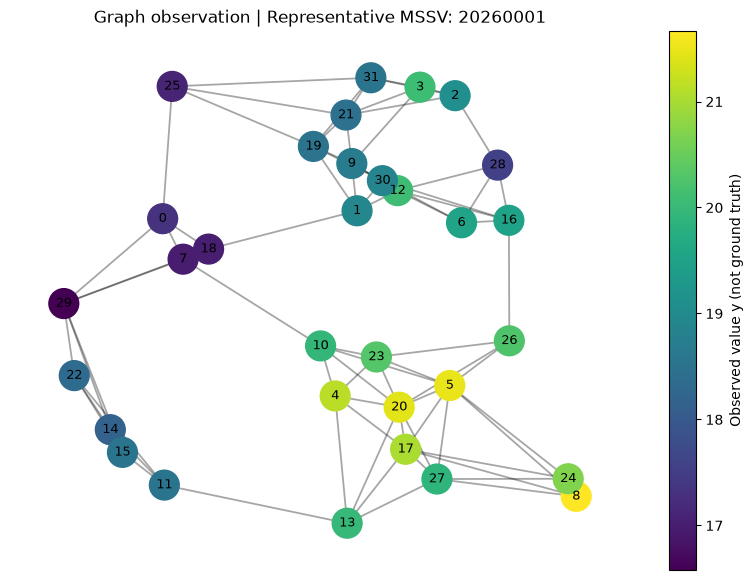

In [3]:
fig, ax = plt.subplots(figsize=(10, 7))
colors = nx.draw_networkx_nodes(
    G, pos=positions, node_color=y, cmap="viridis",
    node_size=460, ax=ax
)
nx.draw_networkx_edges(G, positions, width=1.3, alpha=0.35, ax=ax)
nx.draw_networkx_labels(G, positions, font_size=9, ax=ax)
fig.colorbar(colors, ax=ax, label="Observed value y (not ground truth)")
ax.set_title(f"Graph observation | Representative MSSV: {MSSV_DAI_DIEN}")
ax.axis("off")
plt.show()

## VI. MODEL EXPLANATION — IMPLEMENTED RECOVERY METHOD

### Assumptions and notation

We assume the unknown signal is reasonably smooth across strongly connected sensors. Measurements are modeled as $y_i=x_i^*+\epsilon_i+o_i$, with approximately independent, centered measurement noise $\epsilon_i$ and occasional large errors $o_i$. These are modeling assumptions, not properties guaranteed by the assignment. The graph and edge weights are treated as known; coordinates are used for visualization. No hidden truth or other student ID is used for selection.

Let $W$ be the weighted adjacency matrix in explicit node order $0,\ldots,n-1$, $D_{ii}=\sum_j W_{ij}$, and $L=D-W$. We use the **unnormalized** Laplacian. For this undirected graph,

$$x^\top Lx=\sum_{\{i,j\}\in E}w_{ij}(x_i-x_j)^2,$$

where each undirected edge is counted once.

### Objective and baselines

The main model balances fidelity to available readings with graph smoothness:

$$\hat{x}=\arg\min_x\left[\frac12\sum_{i\in T}(x_i-y_i)^2+\frac\lambda2x^\top Lx\right].$$

Here $T$ is the set of observed training nodes and $\lambda>0$ controls smoothing. Small values preserve detail and noise; large values can erase real differences. With $M_{ii}=1$ for $i\in T$ and zero otherwise, the solution satisfies

$$(M+\lambda L)\hat{x}=My.$$

The implementation solves this system directly with `numpy.linalg.solve`; it never forms a matrix inverse. With all observations, $M=I$. Connectedness and at least one observed node make this quadratic system positive definite. Subtracting a training-only median before solving improves numerical stability; the median is added back afterward.

We compare this model with **weighted neighbor averaging**, $\hat{x}_i=\sum_jW_{ij}y_j/\sum_jW_{ij}$. With no self-loops, this prediction already excludes node $i$'s own reading, so it is also its leave-one-node-out prediction.

The **Huber variant** replaces quadratic fidelity by $\sum_{i\in T}\rho_\delta(x_i-y_i)$, where

$$\rho_\delta(r)=\begin{cases}\frac12r^2,&|r|\leq\delta,\\ \delta|r|-\frac12\delta^2,&|r|>\delta.\end{cases}$$

The linear tail limits the influence of large residuals. We use iteratively reweighted least squares (IRLS), initialized by quadratic smoothing. At each iteration, observed nodes receive weights $q_i=\min(1,\delta/|x_i-y_i|)$, with weight 1 at zero residual; withheld nodes always receive weight zero. We solve $(\operatorname{diag}(q)+\lambda L)x=\operatorname{diag}(q)y$ and repeat. Each subproblem is positive definite. The Huber objective is convex; its gradient provides a direct optimality check.

### Parameter selection without hidden answers

We use **leave-one-node-out validation** on the single assigned case. For each withheld node, its reading is removed before initialization, noise-scale estimation, fitting, and convergence checks. The graph is retained. Each fit predicts that node from the remaining measurements; validation reports RMSE and MAE against the withheld *noisy observations*.

The initial smoothing grid is `0.003, 0.01, 0.03, 0.1, 0.3, 1, 3`. Each model's search extends an endpoint by a factor of ten when its best score lies there, for up to three extensions. Any remaining endpoint optimum is reported for review. We do not choose a representative by comparing cases.

For each training set, estimate a measurement-scale heuristic from neighbor residuals $r_i=y_i-\sum_{j\in T}W_{ij}y_j/\sum_{j\in T}W_{ij}$, using training nodes with available training neighbors. Set $s=1.4826\operatorname{median}|r_i-\operatorname{median}(r)|$. If too few neighbor residuals exist, use the centered training readings; if the scale vanishes, use their MAD and then a numerical floor of $10^{-8}$. These residuals include neighbor noise and possible true variation, so $s$ is not an exact noise standard deviation.

Huber candidates use $\delta=\alpha s$ with fixed factors $\alpha\in\{0.75,1.5,3\}$. The scale is recomputed separately in every validation fold. We first choose the lower-RMSE quadratic or neighbor model, favoring quadratic on an exact tie. Huber is selected only if its best RMSE is at least **1% lower** than that choice. This predeclared practical cutoff favors the simpler method when differences are small; it is not a significance test. Finally, refit the chosen method on **all** readings, recomputing the Huber scale if needed, to obtain `x_hat`.

### Convergence, experiments, and checks

IRLS permits at most 500 linear solves. It stops when both relative iterate change and scaled infinity norm of the objective gradient are at most $10^{-8}$. The code records objective values, checks that they do not increase beyond numerical tolerance, and records the final gradient and iteration count. Nonconverged validation candidates are excluded; a nonconverged final fit prevents export.

Section VII prints the best validation scores, chosen parameters, correction size, graph roughness before and after fitting, and convergence diagnostics. It plots observations and estimates on one color scale, the correction `x_hat - y`, readings by node ID, and validation curves. Full scores, held-out predictions, a JSON diagnostics record, and figure files are saved in `results_<representative ID>/`. These are supporting artifacts, not additional required submission files. Section VIII checks and exports one finite prediction per node in the required CSV format.

### Limitations and interpretation

The true signal may have discontinuities or patterns the graph cannot represent; quadratic smoothness can blur them. Huber downweighting can also suppress a genuine local feature. Neighbor averaging can import a nearby outlier. Small samples, outliers, correlated noise, and heterogeneous sensor precision can distort validation. The score used to choose the method is optimistically biased by selection on those same validation data. Neither validation RMSE nor distance from `y` is the instructor's recovery RMSE. Actual accuracy remains unknown because `x_true` is unavailable. Inspect the outputs and replace the example group IDs before submitting.

### References

- Shuman et al., [The Emerging Field of Signal Processing on Graphs](https://arxiv.org/abs/1211.0053), for graph smoothness and Laplacian methods.
- [SciPy's Huber-loss definition](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.huber.html), for the piecewise loss; the implementation below uses NumPy directly and does not require SciPy.
- [NumPy linear-system solver](https://numpy.org/doc/stable/reference/generated/numpy.linalg.solve.html) and [NetworkX adjacency conversion](https://networkx.org/documentation/stable/reference/generated/networkx.convert_matrix.to_numpy_array.html), for the numerical APIs.


## VII. SOLUTION CODE — reproducible model comparison and recovery

Run every cell below in order. The implementation is contained in this notebook; no local solver module is needed.


In [4]:
import numpy as np
import networkx as nx


def prepare_graph(graph, observations):
    """Validate the assignment data and preserve explicit node order 0, ..., n-1."""
    y_values = np.asarray(observations, dtype=float)
    n = graph.number_of_nodes()
    if graph.is_directed() or graph.is_multigraph() or n < 2:
        raise ValueError('Use a simple undirected graph with at least two nodes.')
    if set(graph.nodes) != set(range(n)):
        raise ValueError('Node IDs must be exactly 0, ..., n-1, matching y.')
    if y_values.shape != (n,) or not np.all(np.isfinite(y_values)):
        raise ValueError('y must contain one finite value per node.')
    if nx.number_of_selfloops(graph) or not nx.is_connected(graph):
        raise ValueError('The graph must be connected and have no self-loops.')
    for _, _, attributes in graph.edges(data=True):
        weight = float(attributes.get('weight', 1.0))
        if not np.isfinite(weight) or weight <= 0:
            raise ValueError('All edge weights must be finite and positive.')
    adjacency = nx.to_numpy_array(
        graph, nodelist=list(range(n)), weight='weight', dtype=float
    )
    laplacian = np.diag(adjacency.sum(axis=1)) - adjacency
    return adjacency, laplacian


def noise_scale(adjacency, observations, observed):
    """MAD of neighbor residuals, using ONLY currently observed readings."""
    observed = np.asarray(observed, dtype=bool)
    training_values = np.asarray(observations, dtype=float)[observed]
    if not len(training_values) or not np.all(np.isfinite(training_values)):
        raise ValueError('At least one finite training observation is required.')
    # Center before averaging, and zero every withheld reading before any product.
    center = np.median(training_values)
    centered = np.zeros(len(observed))
    centered[observed] = training_values - center
    training_adjacency = adjacency * observed[:, None] * observed[None, :]
    degrees = training_adjacency.sum(axis=1)
    usable = observed & (degrees > 0)
    if np.count_nonzero(usable) >= 3:
        residuals = centered[usable] - (
            training_adjacency @ centered
        )[usable] / degrees[usable]
    else:
        residuals = training_values - center
    scale = 1.4826 * np.median(np.abs(residuals - np.median(residuals)))
    if scale < 1e-8:
        scale = 1.4826 * np.median(np.abs(training_values - center))
    return float(max(scale, 1e-8))


def fit_graph_signal(laplacian, observations, smoothing, delta=np.inf,
                     observed=None, tolerance=1e-8, max_iterations=500):
    """Solve the masked quadratic/Huber objective with IRLS diagnostics.

    laplacian must come from prepare_graph. Withheld y entries may be NaN:
    they are never used for initialization, fitting, or stopping criteria.
    """
    y_values = np.asarray(observations, dtype=float)
    L = np.asarray(laplacian, dtype=float)
    if y_values.ndim != 1 or L.shape != (len(y_values), len(y_values)):
        raise ValueError('L and y have incompatible shapes.')
    if (not np.all(np.isfinite(L)) or not np.allclose(L, L.T)
            or not np.allclose(L.sum(axis=1), 0)):
        raise ValueError('A finite, symmetric graph Laplacian is required.')
    if not np.isfinite(smoothing) or smoothing <= 0:
        raise ValueError('smoothing must be finite and strictly positive.')
    if np.isnan(delta) or delta <= 0:
        raise ValueError('delta must be strictly positive, or positive infinity.')
    if not np.isfinite(tolerance) or tolerance <= 0 or max_iterations < 1:
        raise ValueError('Use a positive tolerance and iteration limit.')
    mask = (np.ones(len(y_values), dtype=bool) if observed is None
            else np.asarray(observed, dtype=bool))
    if mask.shape != y_values.shape or not mask.any():
        raise ValueError('The observation mask must select at least one node.')
    if not np.all(np.isfinite(y_values[mask])):
        raise ValueError('Training observations must be finite.')
    # Removing the offset improves numerical stability and preserves constants.
    offset = float(np.median(y_values[mask]))
    target = np.zeros_like(y_values)
    target[mask] = y_values[mask] - offset
    x = np.linalg.solve(np.diag(mask.astype(float)) + smoothing * L, target)

    def diagnostics(vector):
        residual = vector[mask] - target[mask]
        if np.isinf(delta):
            loss = 0.5 * np.sum(residual ** 2)
            influence = residual
        else:
            absolute = np.abs(residual)
            small = absolute <= delta
            loss = (0.5 * np.sum(residual[small] ** 2)
                    + np.sum(delta * (absolute[~small] - 0.5 * delta)))
            influence = np.clip(residual, -delta, delta)
        gradient = smoothing * (L @ vector)
        gradient[mask] += influence
        relative_gradient = np.linalg.norm(gradient, ord=np.inf) / max(
            1.0, np.max(np.abs(influence))
        )
        objective = float(loss + 0.5 * smoothing * (vector @ L @ vector))
        return objective, float(relative_gradient)

    objective, gradient = diagnostics(x)
    history = [objective]
    converged = gradient <= tolerance
    iterations = 1
    if not np.isinf(delta) and not converged:
        for _ in range(max_iterations - 1):
            weights = np.zeros_like(y_values)
            absolute = np.abs(x[mask] - target[mask])
            weights[mask] = np.minimum(1.0, delta / np.maximum(absolute, delta))
            updated = np.linalg.solve(
                np.diag(weights) + smoothing * L, weights * target
            )
            relative_change = np.linalg.norm(updated - x) / max(1.0, np.linalg.norm(x))
            objective, gradient = diagnostics(updated)
            if objective > history[-1] + 1e-9 * max(1.0, abs(history[-1])):
                raise RuntimeError('IRLS increased the objective unexpectedly.')
            history.append(objective)
            x = updated
            iterations += 1
            if relative_change <= tolerance and gradient <= tolerance:
                converged = True
                break
    final_weights = np.zeros_like(y_values)
    if np.isinf(delta):
        final_weights[mask] = 1.0
    else:
        final_weights[mask] = np.minimum(
            1.0, delta / np.maximum(np.abs(x[mask] - target[mask]), delta)
        )
    return {
        'x': x + offset, 'converged': converged, 'iterations': iterations,
        'relative_gradient': gradient, 'objective_history': history,
        'weights': final_weights,
    }


def evaluate_methods(adjacency, laplacian, observations, smoothing_grid=None,
                     huber_factors=(0.75, 1.5, 3.0), max_expansions=3,
                     robust_improvement=0.01):
    """Leave-one-node-out comparison, followed by an all-observation refit."""
    y_values = np.asarray(observations, dtype=float)
    n = len(y_values)
    if y_values.shape != (adjacency.shape[0],) or not np.all(np.isfinite(y_values)):
        raise ValueError('Provide one finite observation per graph node.')
    grid = np.asarray(
        [0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
        if smoothing_grid is None else smoothing_grid, dtype=float
    )
    if grid.ndim != 1 or len(grid) < 2 or not np.all(np.isfinite(grid) & (grid > 0)):
        raise ValueError('Provide at least two finite positive smoothing strengths.')
    factors = np.asarray(huber_factors, dtype=float)
    if factors.ndim != 1 or not len(factors) or not np.all(np.isfinite(factors) & (factors > 0)):
        raise ValueError('Huber factors must be finite and positive.')
    if max_expansions < 0 or not 0 <= robust_improvement < 1:
        raise ValueError('Invalid expansion limit or improvement threshold.')
    masks = ~np.eye(n, dtype=bool)
    scales = np.array([noise_scale(adjacency, y_values, mask) for mask in masks])
    rows = []

    def metrics(predictions):
        errors = predictions - y_values
        return float(np.sqrt(np.mean(errors ** 2))), float(np.mean(np.abs(errors)))

    def search(method, factor=None):
        candidates = set(map(float, grid))
        evaluated = {}
        for expansion in range(max_expansions + 1):
            for smoothing in sorted(candidates - evaluated.keys()):
                predictions = np.empty(n)
                converged_folds = 0
                largest_iterations = 0
                for held_out, mask in enumerate(masks):
                    delta = np.inf if factor is None else factor * scales[held_out]
                    fit = fit_graph_signal(laplacian, y_values, smoothing, delta, mask)
                    predictions[held_out] = fit['x'][held_out]
                    converged_folds += int(fit['converged'])
                    largest_iterations = max(largest_iterations, fit['iterations'])
                rmse, mae = metrics(predictions)
                if converged_folds != n:
                    rmse = mae = float('inf')
                row = {
                    'method': method, 'smoothing': smoothing, 'factor': factor,
                    'rmse': rmse, 'mae': mae, 'predictions': predictions,
                    'converged_folds': converged_folds, 'max_iterations': largest_iterations,
                }
                rows.append(row)
                evaluated[smoothing] = row
            best = min(evaluated.values(), key=lambda row: (row['rmse'], row['smoothing']))
            if not np.isfinite(best['rmse']):
                raise RuntimeError(f'No {method} candidate converged in every fold.')
            lower, upper = min(candidates), max(candidates)
            at_lower = best['smoothing'] == lower
            at_upper = best['smoothing'] == upper
            if expansion == max_expansions or not (at_lower or at_upper):
                break
            candidates.add(lower / 10 if at_lower else upper * 10)
        best = dict(best)
        best['boundary'] = at_lower or at_upper
        return best

    neighbor_predictions = (adjacency @ y_values) / adjacency.sum(axis=1)
    rmse, mae = metrics(neighbor_predictions)
    neighbor = {
        'method': 'neighbors', 'smoothing': None, 'factor': None,
        'rmse': rmse, 'mae': mae, 'predictions': neighbor_predictions,
        'converged_folds': n, 'max_iterations': 0, 'boundary': False,
    }
    rows.append(neighbor)
    quadratic = search('quadratic')
    robust_options = [search('huber', float(factor)) for factor in factors]
    best_robust = min(robust_options, key=lambda row: row['rmse'])
    selected = min((quadratic, neighbor), key=lambda row: row['rmse'])
    # A declared practical threshold, rather than a claim of statistical significance.
    if best_robust['rmse'] < (1 - robust_improvement) * selected['rmse']:
        selected = best_robust
    observed = np.ones(n, dtype=bool)
    final_scale = noise_scale(adjacency, y_values, observed)
    if selected['method'] == 'neighbors':
        final_fit, delta = None, None
        x_hat = neighbor_predictions.copy()
    else:
        delta = (np.inf if selected['method'] == 'quadratic'
                 else selected['factor'] * final_scale)
        final_fit = fit_graph_signal(
            laplacian, y_values, selected['smoothing'], delta
        )
        if not final_fit['converged']:
            raise RuntimeError('The final all-observation fit did not converge.')
        x_hat = final_fit['x']
    if x_hat.shape != y_values.shape or not np.all(np.isfinite(x_hat)):
        raise RuntimeError('The selected model produced invalid predictions.')
    return {
        'x_hat': x_hat, 'selected': selected, 'rows': rows,
        'best_models': [neighbor, quadratic, best_robust],
        'final_fit': final_fit, 'scale': final_scale, 'delta': delta,
    }


In [5]:
# Run only after loading the group's assigned G and y in Section IV.
W, L = prepare_graph(G, y)
recovery = evaluate_methods(W, L, y)
x_hat = recovery['x_hat']
selected = recovery['selected']
results_dir = Path(f'results_{MSSV_DAI_DIEN}')
results_dir.mkdir(exist_ok=True)

print('Leave-one-node-out validation against NOISY readings (not hidden truth):')
print(f"{'Method':<14} {'lambda':>10} {'Huber factor':>14} {'RMSE':>10} {'MAE':>10}")
for row in recovery['best_models']:
    smoothing = '-' if row['smoothing'] is None else f"{row['smoothing']:.6g}"
    factor = '-' if row['factor'] is None else f"{row['factor']:.3g}"
    print(f"{row['method']:<14} {smoothing:>10} {factor:>14} {row['rmse']:>10.6f} {row['mae']:>10.6f}")
print(f"Selected: {selected['method']} | lambda: {selected['smoothing']}")
for row in recovery['best_models']:
    if row['boundary']:
        print(f"Review: the best {row['method']} score remains at a search endpoint.")
print(f"Training scale heuristic: {recovery['scale']:.6g}")
if selected['method'] == 'huber':
    print(f"Selected Huber delta: {recovery['delta']:.6g}")
print(f"Graph roughness y^T L y: {y @ L @ y:.6f}")
print(f"Graph roughness x_hat^T L x_hat: {x_hat @ L @ x_hat:.6f}")
print(f"RMS correction relative to y: {np.sqrt(np.mean((x_hat - y)**2)):.6f}")
fit = recovery['final_fit']
if fit is not None:
    print(f"Final fit: converged={fit['converged']}, solves={fit['iterations']}, "
          f"scaled gradient={fit['relative_gradient']:.3e}")
    print('Downweighted observations (not confirmed outliers):',
          np.flatnonzero(fit['weights'] < 1 - 1e-8).tolist())
print('Verify the example student IDs in Section III before submission.')

# Save validation evidence separately from the mandatory prediction file.
import csv
score_fields = ['method', 'smoothing', 'factor', 'rmse', 'mae',
                'converged_folds', 'max_iterations']
with (results_dir / 'validation_scores.csv').open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=score_fields)
    writer.writeheader()
    writer.writerows({key: row[key] for key in score_fields} for row in recovery['rows'])
with (results_dir / 'heldout_predictions.csv').open('w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['node_id', 'noisy_observation', 'heldout_prediction', 'residual'])
    for node_id, (observation, prediction) in enumerate(zip(y, selected['predictions'])):
        writer.writerow([node_id, observation, prediction, prediction - observation])
summary = {
    'representative_mssv': MSSV_DAI_DIEN,
    'group_mssvs': NHOM_MSSV,
    'assigned_case_id': assign_mssv_to_case(MSSV_DAI_DIEN, _case_db),
    'dataset_sha256': hashlib.sha256(Path('public_cases.json').read_bytes()).hexdigest(),
    'node_count': len(y),
    'method': selected['method'],
    'smoothing': selected['smoothing'],
    'huber_factor': selected['factor'],
    'huber_delta': recovery['delta'] if selected['method'] == 'huber' else None,
    'validation_rmse_noisy_observations': selected['rmse'],
    'validation_mae_noisy_observations': selected['mae'],
    'ground_truth_rmse': None,
    'search_endpoint': selected['boundary'],
    'all_best_models': [{k: v for k, v in row.items() if k != 'predictions'}
                        for row in recovery['best_models']],
    'converged': fit['converged'] if fit is not None else None,
    'linear_solves': fit['iterations'] if fit is not None else 0,
    'scaled_gradient': fit['relative_gradient'] if fit is not None else None,
    'objective_history': fit['objective_history'] if fit is not None else [],
    'numpy_version': np.__version__, 'networkx_version': nx.__version__,
}
(results_dir / 'diagnostics.json').write_text(
    json.dumps(summary, indent=2, allow_nan=False) + '\n', encoding='utf-8'
)


Leave-one-node-out validation against NOISY readings (not hidden truth):
Method             lambda   Huber factor       RMSE        MAE
neighbors               -              -   0.735080   0.594585
quadratic             0.1              -   0.730948   0.582250
huber                 0.1            1.5   0.730948   0.582250
Selected: quadratic | lambda: 0.1
Training scale heuristic: 0.674784
Graph roughness y^T L y: 73.649978
Graph roughness x_hat^T L x_hat: 40.196081
RMS correction relative to y: 0.203060
Final fit: converged=True, solves=1, scaled gradient=9.853e-16
Downweighted observations (not confirmed outliers): []
Verify the example student IDs in Section III before submission.


1508

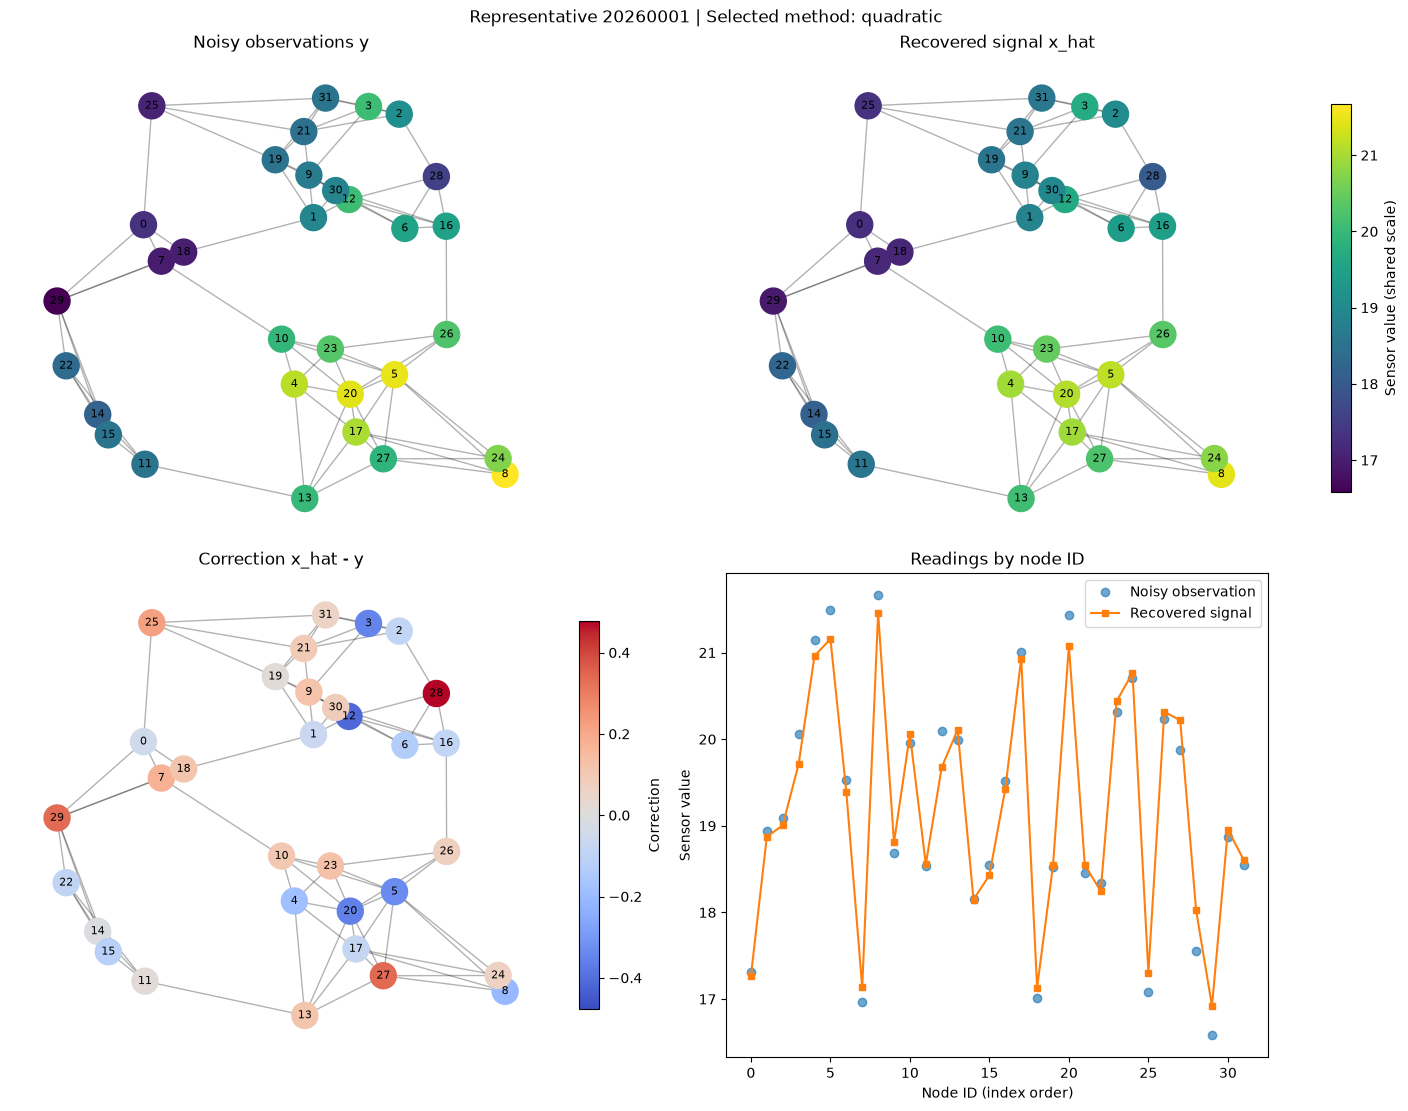

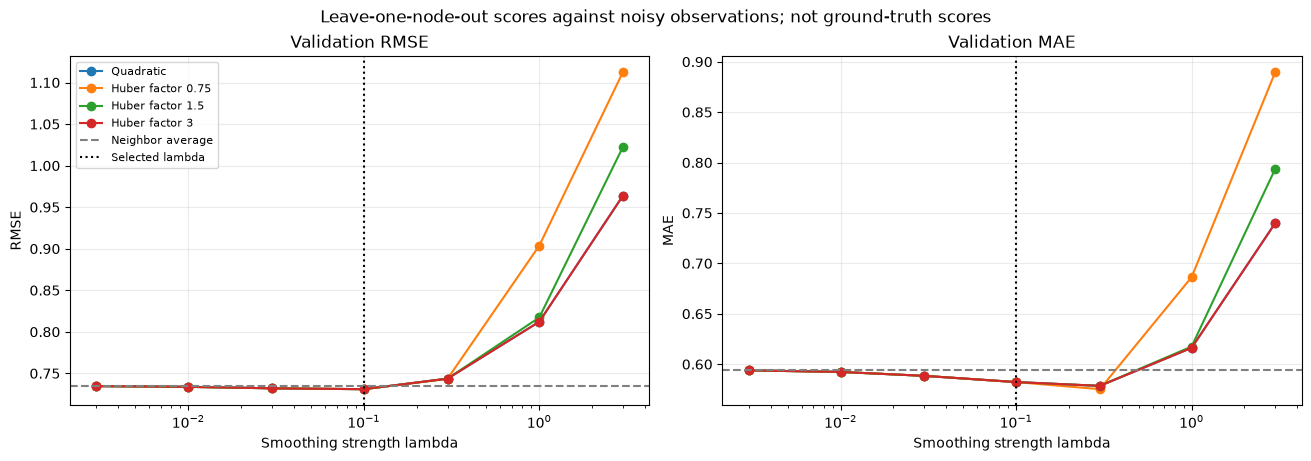

In [6]:
# Observation and estimate maps use the same color scale.
fig, axes = plt.subplots(2, 2, figsize=(14, 11), constrained_layout=True)
nodes = list(range(len(y)))
vmin, vmax = float(min(y.min(), x_hat.min())), float(max(y.max(), x_hat.max()))
for ax, values, title in zip(axes[0], [y, x_hat], ['Noisy observations y', 'Recovered signal x_hat']):
    nx.draw_networkx_edges(G, positions, ax=ax, alpha=0.3)
    colors = nx.draw_networkx_nodes(
        G, positions, nodelist=nodes, node_color=values, cmap='viridis',
        vmin=vmin, vmax=vmax, node_size=350, ax=ax
    )
    nx.draw_networkx_labels(G, positions, ax=ax, font_size=8)
    ax.set_title(title)
    ax.axis('off')
fig.colorbar(colors, ax=list(axes[0]), label='Sensor value (shared scale)', shrink=0.8)
correction = x_hat - y
limit = max(float(np.max(np.abs(correction))), 1e-8)
nx.draw_networkx_edges(G, positions, ax=axes[1, 0], alpha=0.3)
colors = nx.draw_networkx_nodes(
    G, positions, nodelist=nodes, node_color=correction, cmap='coolwarm',
    vmin=-limit, vmax=limit, node_size=350, ax=axes[1, 0]
)
nx.draw_networkx_labels(G, positions, ax=axes[1, 0], font_size=8)
axes[1, 0].set_title('Correction x_hat - y')
axes[1, 0].axis('off')
fig.colorbar(colors, ax=axes[1, 0], label='Correction', shrink=0.8)
axes[1, 1].plot(nodes, y, 'o', alpha=0.65, label='Noisy observation')
axes[1, 1].plot(nodes, x_hat, 's-', markersize=4, label='Recovered signal')
axes[1, 1].set(xlabel='Node ID (index order)', ylabel='Sensor value', title='Readings by node ID')
axes[1, 1].legend()
fig.suptitle(f"Representative {MSSV_DAI_DIEN} | Selected method: {selected['method']}")
fig.savefig(results_dir / 'signal_recovery.png', dpi=160)
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for method, factor in [('quadratic', None), ('huber', 0.75), ('huber', 1.5), ('huber', 3.0)]:
    rows = sorted(
        [row for row in recovery['rows'] if row['method'] == method and row['factor'] == factor],
        key=lambda row: row['smoothing']
    )
    label = 'Quadratic' if factor is None else f'Huber factor {factor:g}'
    for ax, metric in zip(axes, ['rmse', 'mae']):
        ax.semilogx([row['smoothing'] for row in rows],
                    [row[metric] for row in rows], 'o-', label=label)
neighbor = recovery['best_models'][0]
for ax, metric in zip(axes, ['rmse', 'mae']):
    ax.axhline(neighbor[metric], linestyle='--', color='gray', label='Neighbor average')
    if selected['smoothing'] is not None:
        ax.axvline(selected['smoothing'], linestyle=':', color='black', label='Selected lambda')
    ax.set(xlabel='Smoothing strength lambda', ylabel=metric.upper(), title=f'Validation {metric.upper()}')
    ax.grid(alpha=0.25)
axes[0].legend(fontsize=8)
fig.suptitle('Leave-one-node-out scores against noisy observations; not ground-truth scores')
fig.savefig(results_dir / 'validation_curves.png', dpi=160)
plt.show()
plt.close(fig)


## VIII. PREDICTION FILE `.csv` — DETAILED FORMAT INSTRUCTIONS

**This file is required.** Filename: `submission_<MSSV_DAI_DIEN>.csv` (for example, `submission_20260001.csv`). Use UTF-8 encoding, commas `,` to separate columns, and periods `.` as decimal separators.

**The following four columns are REQUIRED and must use these exact names:**

| Column | Contents / rules |
|---|---|
| `representative_mssv` | The representative's student ID, **repeated identically** on every row |
| `group_mssvs` | **All** group members' student IDs, joined with `\|` (for example, `20260001\|20260002\|20260003`), repeated on every row |
| `node_id` | Integer node ID from `0` to `n-1`, **with no missing or duplicate nodes** |
| `x_hat` | A finite real-valued prediction for the corresponding `node_id` |

Example showing **the first three data rows** (the actual file must contain all 32 data rows, for nodes 0 through 31):

```csv
representative_mssv,group_mssvs,node_id,x_hat
20260001,20260001|20260002|20260003,0,19.52145678
20260001,20260001|20260002|20260003,1,19.33710245
20260001,20260001|20260002|20260003,2,19.89653412
```

If you computed `x_hat` in Python, run the helper code below to create a correctly formatted file. If you computed it elsewhere, you may create the CSV yourself using this exact structure. **Do not submit the unprocessed observation vector `y` as your answer.**


In [7]:
import csv


def save_submission(x_hat, representative_mssv=None, group_mssvs=None):
    """Validate and export the four required columns, preserving student IDs."""
    representative = str(MSSV_DAI_DIEN if representative_mssv is None else representative_mssv).strip()
    group = NHOM_MSSV if group_mssvs is None else group_mssvs
    pred = np.asarray(x_hat, dtype=float).reshape(-1)
    if pred.shape != y.shape or not np.all(np.isfinite(pred)):
        raise ValueError(f'x_hat must contain exactly {len(y)} finite real numbers')
    ids = [str(value).strip() for value in group]
    if (not ids or not all(ids) or len(ids) != len(set(ids))
            or representative not in ids or any('|' in value for value in ids)):
        raise ValueError('Provide nonempty, unique student IDs including the representative; IDs cannot contain |.')
    if representative != loaded_representative_mssv:
        raise ValueError('The representative changed: rerun Sections IV through VII before export.')
    filename = f'submission_{representative}.csv'
    with open(filename, 'w', newline='', encoding='utf-8-sig') as f:
        writer = csv.writer(f)
        writer.writerow(['representative_mssv', 'group_mssvs', 'node_id', 'x_hat'])
        for node_id, value in enumerate(pred):
            writer.writerow([representative, '|'.join(ids), node_id, f'{float(value):.10f}'])
    print(f'Exported {filename} with {len(pred)} predictions.')
    print('SUBMIT: the completed original notebook + this CSV.')
    print('Replace example IDs and review the method explanation and outputs before submitting.')
    return filename


In [8]:
submission_file = save_submission(x_hat)


Exported submission_20260001.csv with 32 predictions.
SUBMIT: the completed original notebook + this CSV.
Replace example IDs and review the method explanation and outputs before submitting.
